# 02 — Laser: equações de taxa e laser quase-monocromático

Este notebook segue a aula (`docs/04-class/context.md`) e o guia `docs/laser.md`. São dois
modelos de laser monomodo:

- **A. Equações de taxa** (modulação direta): a corrente injetada I(t) controla a densidade
  de portadores N(t) e a densidade de fótons S(t), o "fluxo de fótons" da aula.
- **B. Quase-monocromático** (modulação externa e oscilador local): laser em corrente
  constante, potência fixa e fase com ruído.

Regras usadas em todas as figuras (as mesmas do notebook da fibra):

- a física simulada vem **sempre** do pacote (`simcopy.kernels.laser`); o notebook só escreve
  as formas fechadas, que são a referência;
- forma fechada (linha) e simulação (pontos) juntas, e o erro em painel próprio;
- as asserções numéricas ficam nos testes do pytest; cada seção indica qual teste garante
  o resultado.

Fontes: Agrawal, *Sistemas de Comunicação por Fibra Óptica*, 4ª ed., cap. 3 (citado pelo
número da equação) e o notebook do professor `2_Laser_sources` (parâmetros e formulação em
densidade).

## 0. Equações e parâmetros

Formulação em densidade (decisão de 2026-10-08), que é a do Agrawal (Eq. 3.3.1, 3.3.2,
3.3.15, 3.3.16) dividida pelo volume V da região ativa:

$$\frac{dS}{dt} = (G - \tau_p^{-1})\,S + R_{sp},\qquad
\frac{dN}{dt} = \frac{I}{qV} - G\,S - \frac{N}{\tau_c},\qquad
\frac{d\phi}{dt} = \frac{\alpha_H}{2}\left[g_c(N - N_{tr}) - \tau_p^{-1}\right]$$

$$G = g_c\,(N - N_{tr})(1 - \varepsilon S),\qquad g_c = \Gamma v_g \sigma_g,\qquad
\tau_p^{-1} = v_g(\alpha_{mir} + \alpha_{int})$$

- O primeiro termo de dS/dt é o ganho líquido: emissão estimulada menos as perdas da
  cavidade. O segundo é a emissão espontânea que cai no modo do laser.
- dN/dt soma a injeção de elétrons e subtrai o consumo por emissão estimulada e a
  recombinação (tempo de vida τ_c).
- A fase varia quando o ganho difere da perda: é o chirp, acoplado pelo fator α_H.

Os parâmetros são os do notebook do professor. As grandezas derivadas (τ_p, limiar, R_sp,
eficiência) vêm de `resolve_rate_equation_laser`, como o resto das grandezas derivadas do
simulador.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simcopy.config.system import RateEquationLaserConfig
from simcopy.config.resolve import resolve_rate_equation_laser
from simcopy.core.units import C_LIGHT, Q_ELECTRON
from simcopy.kernels.laser.rate_equations import (RateEquationParams, gain, steady_state,
                                                  integrate)
from simcopy.kernels.laser.conversions import facet_power
from simcopy.kernels.laser.cw import cw_field

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C3 = ["tab:blue", "tab:orange", "tab:green"]
C4 = C3 + ["tab:red"]

CFG = RateEquationLaserConfig(
    cavity_length=300e-6, cavity_width=3e-6, cavity_height=0.2e-6, group_index=3.4,
    mirror_loss=2410.0, internal_loss=1510.0, differential_gain=4e-20,
    transparency_density=1.25e24, confinement=1.0, carrier_lifetime=2.1e-9,
    spontaneous_emission_factor=1.5, gain_compression=0.0, linewidth_enhancement=3.0)
F_LASER = C_LIGHT / 1550e-9
R = resolve_rate_equation_laser(CFG, F_LASER)

def params(cfg, r, **mudancas):
    """Números que o kernel recebe (o bloco do componente fará este mapeamento)."""
    base = dict(gain_coefficient=r.gain_coefficient,
                transparency_density=cfg.transparency_density,
                photon_lifetime=r.photon_lifetime, carrier_lifetime=cfg.carrier_lifetime,
                volume=r.volume, spontaneous_emission_rate=r.spontaneous_emission_rate,
                gain_compression=cfg.gain_compression,
                linewidth_enhancement=cfg.linewidth_enhancement)
    base.update(mudancas)
    return RateEquationParams(**base)

P = params(CFG, R)

def potencia(s):
    """Potência emitida por faceta [W], Agrawal Eq. 3.3.8 com P = S*V."""
    return facet_power(s, R.volume, R.group_velocity, CFG.mirror_loss, R.photon_energy)

print(f"V = {R.volume:.3e} m³ | τ_p = {R.photon_lifetime*1e12:.4f} ps | "
      f"N_th = {R.threshold_density:.4e} m⁻³ | I_th = {R.threshold_current*1e3:.3f} mA")
print(f"R_sp = {R.spontaneous_emission_rate:.3e} m⁻³s⁻¹ | η_d = {R.differential_efficiency:.4f} | "
      f"dP_e/dI = {R.slope_efficiency:.4f} W/A por faceta")

ImportError: cannot import name 'RateEquationLaserConfig' from 'simcopy.config.system' (C:\Users\bozel\Área de Trabalho\simcopy\repo\src\simcopy\config\system.py)

## 1. Ganho, perda e limiar

**Conceito.** O laser começa a emitir quando o ganho iguala a perda da cavidade:
$g_c(N_{th} - N_{tr}) = \tau_p^{-1}$. Daí

$$N_{th} = N_{tr} + \frac{1}{g_c\,\tau_p},\qquad I_{th} = \frac{q\,N_{th}\,V}{\tau_c}
\quad\text{(Agrawal, Eq. 3.3.6)}$$

Abaixo da transparência ($N < N_{tr}$) o ganho é negativo: o meio absorve.

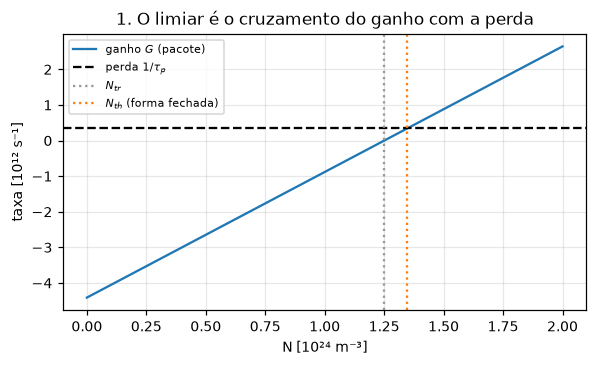

In [ ]:
n_eixo = np.linspace(0, 2e24, 201)
fig, ax = plt.subplots(1, 1, figsize=(5.5, 3.4))
ax.plot(n_eixo / 1e24, gain(n_eixo, 0.0, P) / 1e12, color=C3[0], label="ganho $G$ (pacote)")
ax.axhline(1 / R.photon_lifetime / 1e12, color="k", ls="--", label=r"perda $1/\tau_p$")
ax.axvline(CFG.transparency_density / 1e24, color="0.6", ls=":", label="$N_{tr}$")
ax.axvline(R.threshold_density / 1e24, color=C3[1], ls=":", label="$N_{th}$ (forma fechada)")
ax.set(xlabel="N [10²⁴ m⁻³]", ylabel="taxa [10¹² s⁻¹]",
       title="1. O limiar é o cruzamento do ganho com a perda")
ax.legend()
fig.tight_layout()

**Leitura.** A reta do ganho corta a perda exatamente em $N_{th}$ calculado pela forma
fechada. A perda é dominada pelos espelhos e pela perda interna; aumentar qualquer uma
encurta τ_p e desloca o limiar para a direita (teste
`config/tests/test_resolve_laser.py::test_resolve_rate_equation_laser_limiar_cresce_com_perda`).

## 2. Estado estacionário: curva $P_{out} \times I$

**Equação.** Em corrente constante as derivadas são nulas. Desprezando $R_{sp}$
(Agrawal, texto antes da Eq. 3.3.6 e Eq. 3.3.7–3.3.10):

- abaixo do limiar: $S = 0$ e $N = \tau_c I/(qV)$;
- acima do limiar: $N = N_{th}$ (o ganho "trava" na perda) e
  $S = \tau_p (I - I_{th})/(qV)$;
- potência por faceta: $P_e = \frac{\hbar\omega}{2q}\,\eta_d\,(I - I_{th})$, com
  $\eta_d = \alpha_{mir}/(\alpha_{mir}+\alpha_{int})$.

A simulação usa `steady_state`, que resolve as equações completas (com $R_{sp}$) sem
assumir a forma acima.

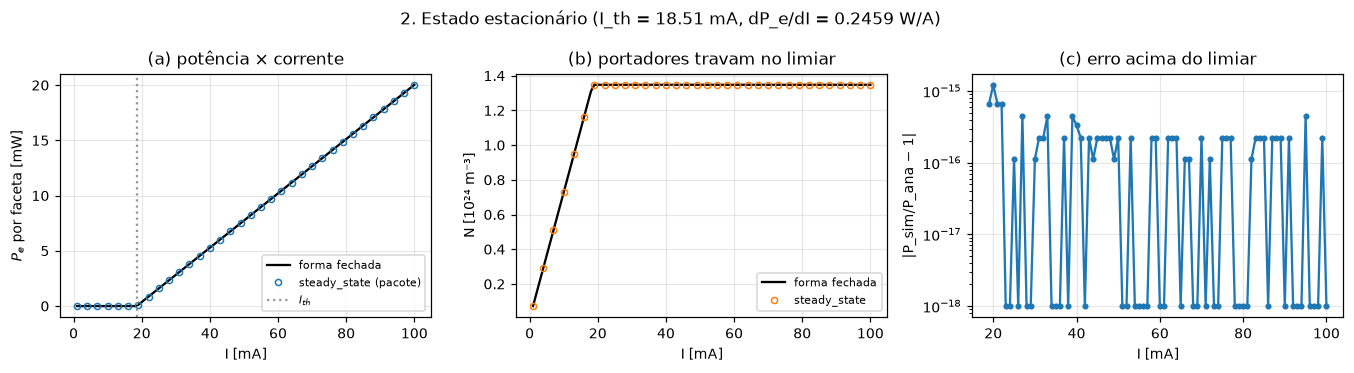

In [ ]:
I_eixo = np.linspace(1e-3, 100e-3, 100)
estac = np.array([steady_state(i, P) for i in I_eixo])
N_ss, S_ss = estac[:, 0], estac[:, 1]
Pe_ss = potencia(S_ss)
acima = I_eixo > R.threshold_current
Pe_ana = np.where(acima, R.slope_efficiency * (I_eixo - R.threshold_current), 0.0)
N_ana = np.where(acima, R.threshold_density, CFG.carrier_lifetime * I_eixo / (Q_ELECTRON * R.volume))

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(I_eixo * 1e3, Pe_ana * 1e3, "-", color="k", label="forma fechada")
ax[0].plot(I_eixo[::3] * 1e3, Pe_ss[::3] * 1e3, "o", ms=4, mfc="none", color=C3[0],
           label="steady_state (pacote)")
ax[0].axvline(R.threshold_current * 1e3, color="0.6", ls=":", label="$I_{th}$")
ax[0].set(xlabel="I [mA]", ylabel="$P_e$ por faceta [mW]", title="(a) potência × corrente")
ax[1].plot(I_eixo * 1e3, N_ana / 1e24, "-", color="k", label="forma fechada")
ax[1].plot(I_eixo[::3] * 1e3, N_ss[::3] / 1e24, "o", ms=4, mfc="none", color=C3[1],
           label="steady_state")
ax[1].set(xlabel="I [mA]", ylabel="N [10²⁴ m⁻³]", title="(b) portadores travam no limiar")
erro = np.abs(Pe_ss[acima] / Pe_ana[acima] - 1)
ax[2].semilogy(I_eixo[acima] * 1e3, erro + 1e-18, "o-", ms=3, color=C3[0])
ax[2].set(xlabel="I [mA]", ylabel="|P_sim/P_ana − 1|", title="(c) erro acima do limiar")
for a in ax[:2]: a.legend()
fig.suptitle(f"2. Estado estacionário (I_th = {R.threshold_current*1e3:.2f} mA, "
             f"dP_e/dI = {R.slope_efficiency:.4f} W/A)")
fig.tight_layout()

**Leitura.** Acima do limiar a potência cresce linearmente com a corrente, e N fica parado
em $N_{th}$: toda corrente adicional vira fótons. O erro fica no arredondamento porque o
$R_{sp}$ do notebook do professor (dividido por 1e40) é desprezível. Abaixo do limiar
a potência é praticamente zero e N cresce linearmente com I.

Testes que garantem: `kernels/laser/tests/test_rate_equations.py`
(`test_steady_state_*`, `test_curva_potencia_corrente`).

## 3. Ligando o laser: $N(t)$ e $S(t)$ para um degrau de corrente

Os gráficos da aula: N × t para uma corrente de polarização, e embaixo o fluxo de fótons
S × t. O laser parte de N = S = 0 e a corrente sobe em degrau em t = 0.

**Forma fechada parcial** [dedução do guia, seção 3.2]: enquanto S ≈ 0, a Eq. de dN/dt
vira $dN/dt = I/(qV) - N/\tau_c$, e N atinge $N_{th}$ no instante
$t_d = \tau_c \ln[I/(I - I_{th})]$ (partindo de N = 0). A partir daí S cresce. Os valores
finais são os do estado estacionário da seção 2.

I = 30 mA: t_d (forma fechada) = 2016 ps; S atinge metade do final em 2422 ps; S final / estacionário = 1.000000


I = 60 mA: t_d (forma fechada) = 775 ps; S atinge metade do final em 989 ps; S final / estacionário = 1.000000


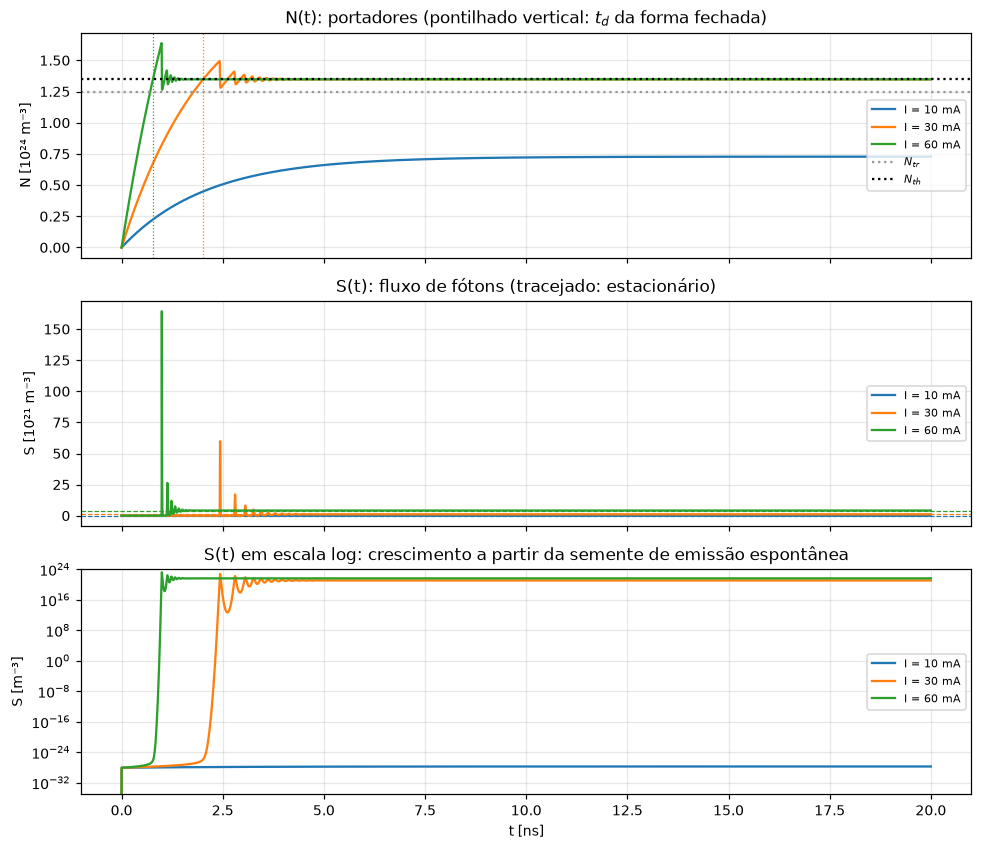

In [ ]:
DT = 1e-12                       # grade de 1 ps; o integrador usa subpassos de 0,1 ps
T_SIM = 20e-9
t = np.arange(int(T_SIM / DT)) * DT
correntes = [10e-3, 30e-3, 60e-3]
fig, ax = plt.subplots(3, 1, figsize=(9, 7.8), sharex=True)
for i, I0 in enumerate(correntes):
    N_t, S_t, _ = integrate(np.full(t.size, I0), DT, P, 0.0, 0.0)
    n_f, s_f = steady_state(I0, P)
    ax[0].plot(t * 1e9, N_t / 1e24, color=C3[i], label=f"I = {I0*1e3:.0f} mA")
    ax[1].plot(t * 1e9, S_t / 1e21, color=C3[i], label=f"I = {I0*1e3:.0f} mA")
    ax[1].axhline(s_f / 1e21, color=C3[i], ls="--", lw=0.8)
    ax[2].semilogy(t * 1e9, np.maximum(S_t, 1e-40), color=C3[i], label=f"I = {I0*1e3:.0f} mA")
    if I0 > R.threshold_current:
        td = CFG.carrier_lifetime * np.log(I0 / (I0 - R.threshold_current))
        ax[0].axvline(td * 1e9, color=C3[i], ls=":", lw=0.8)
        k = np.argmax(S_t > 0.5 * s_f)
        print(f"I = {I0*1e3:.0f} mA: t_d (forma fechada) = {td*1e12:.0f} ps; "
              f"S atinge metade do final em {t[k]*1e12:.0f} ps; "
              f"S final / estacionário = {S_t[-1]/s_f:.6f}")
ax[0].axhline(CFG.transparency_density / 1e24, color="0.6", ls=":", label="$N_{tr}$")
ax[0].axhline(R.threshold_density / 1e24, color="k", ls=":", label="$N_{th}$")
ax[0].set(ylabel="N [10²⁴ m⁻³]", title="N(t): portadores (pontilhado vertical: $t_d$ da forma fechada)")
ax[1].set(ylabel="S [10²¹ m⁻³]", title="S(t): fluxo de fótons (tracejado: estacionário)")
ax[2].set(xlabel="t [ns]", ylabel="S [m⁻³]", ylim=(1e-35, 1e24),
          title="S(t) em escala log: crescimento a partir da semente de emissão espontânea")
for a in ax: a.legend(loc="right")
fig.tight_layout()

**Leitura.**
- Em 10 mA (abaixo do limiar) N sobe até $\tau_c I/(qV)$, abaixo até de $N_{tr}$, e não há
  emissão.
- Em 30 e 60 mA, N passa de $N_{th}$, os fótons crescem, consomem portadores, e N volta ao
  limiar oscilando: são as **oscilações de relaxação** (seção 4). Depois de alguns
  nanossegundos S chega ao estacionário da seção 2.
- A fórmula de $t_d$ acerta o instante em que N cruza $N_{th}$ (linhas pontilhadas no
  painel de cima). A luz, porém, só aparece algumas centenas de ps depois (ver a saída da
  célula): acima do limiar S cresce exponencialmente, mas parte de zero e tem só a emissão
  espontânea como semente. O painel em escala log mostra esse crescimento por dezenas de
  ordens de grandeza. Com o $R_{sp}$ do notebook do professor (≈ 4e-16 m⁻³s⁻¹) a semente
  é minúscula; $R_{sp}$ controla, portanto, quanto tempo o laser leva para ligar além de
  $t_d$. Durante esse tempo N continua subindo acima de $N_{th}$, o que explica o primeiro
  pico de fótons muito acima do estacionário.

Testes que garantem: `test_integrate_degrau_converge_para_o_estacionario`,
`test_integrate_estacionario_e_ponto_fixo`.

## 4. Oscilações de relaxação

**Forma fechada** (Agrawal, Eq. 3.3.20–3.3.21, em densidade): perto do estacionário,
uma pequena perturbação oscila com frequência $\Omega_R$ e decai com taxa $\Gamma_R$:

$$\Omega_R = \left[G\,g_c S - \tfrac{(\Gamma_P - \Gamma_N)^2}{4}\right]^{1/2},\quad
\Gamma_R = \tfrac{\Gamma_P + \Gamma_N}{2},\quad
\Gamma_P = \tfrac{R_{sp}}{S} + \varepsilon G S,\quad \Gamma_N = \tfrac{1}{\tau_c} + g_c S$$

Como S cresce com a corrente, $\Omega_R$ também cresce: é por isso que polarizar o laser
mais alto aumenta a banda de modulação (Eq. 3.3.24). A simulação aplica um degrau de
+1 mA a partir do estacionário e mede a frequência pelos cruzamentos de zero de
$S(t) - S_{final}$.

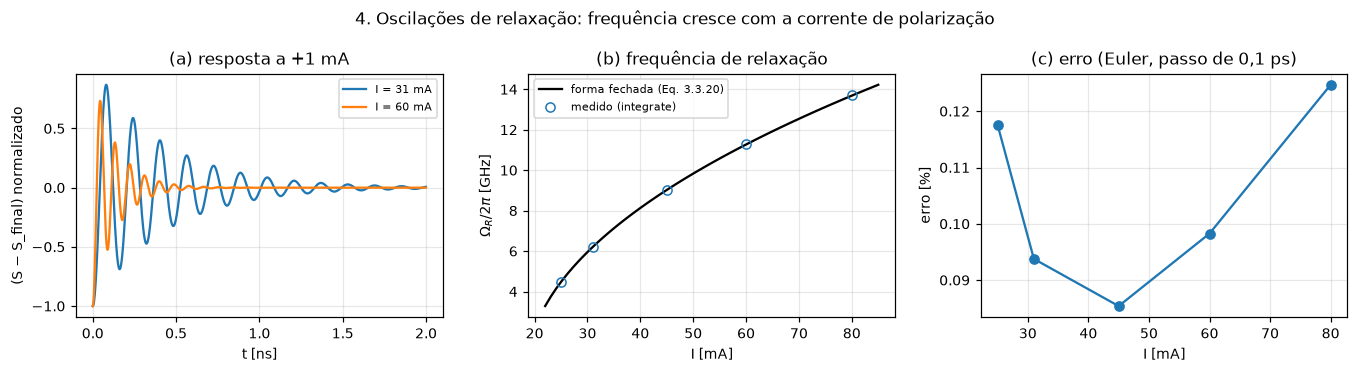

In [ ]:
def omega_gamma_ana(I0):
    s = steady_state(I0, P)[1]
    G = 1 / P.photon_lifetime - P.spontaneous_emission_rate / s
    gp = P.spontaneous_emission_rate / s + P.gain_compression * G * s
    gn = 1 / P.carrier_lifetime + P.gain_coefficient * s
    return np.sqrt(G * P.gain_coefficient * s - (gp - gn) ** 2 / 4), (gp + gn) / 2

def omega_medido(I0, n=8000):
    n0, s0 = steady_state(I0 - 1e-3, P)
    _, S_t, _ = integrate(np.full(n, I0), DT, P, n0, s0)
    x = S_t - steady_state(I0, P)[1]
    i = np.where(np.diff(np.sign(x)) != 0)[0][:9]
    cz = i * DT - x[i] * DT / (x[i + 1] - x[i])
    return 2 * np.pi / (2 * np.mean(np.diff(cz))), x

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
I_bias = np.array([25e-3, 31e-3, 45e-3, 60e-3, 80e-3])
med, ana = [], []
for i, I0 in enumerate(I_bias):
    om, x = omega_medido(I0)
    med.append(om); ana.append(omega_gamma_ana(I0)[0])
    if i in (1, 3):
        tt = np.arange(x.size) * DT
        ax[0].plot(tt[:2000] * 1e9, x[:2000] / abs(x[0]), color=C3[i // 2],
                   label=f"I = {I0*1e3:.0f} mA")
I_fino = np.linspace(22e-3, 85e-3, 60)
ax[1].plot(I_fino * 1e3, [omega_gamma_ana(i)[0] / 2 / np.pi / 1e9 for i in I_fino], "k-",
           label="forma fechada (Eq. 3.3.20)")
ax[1].plot(I_bias * 1e3, np.array(med) / 2 / np.pi / 1e9, "o", mfc="none", color=C3[0],
           label="medido (integrate)")
ax[2].plot(I_bias * 1e3, np.abs(np.array(med) / np.array(ana) - 1) * 100, "o-", color=C3[0])
ax[0].set(xlabel="t [ns]", ylabel="(S − S_final) normalizado", title="(a) resposta a +1 mA")
ax[1].set(xlabel="I [mA]", ylabel="$\\Omega_R/2\\pi$ [GHz]", title="(b) frequência de relaxação")
ax[2].set(xlabel="I [mA]", ylabel="erro [%]", title="(c) erro (Euler, passo de 0,1 ps)")
for a in ax[:2]: a.legend()
fig.suptitle("4. Oscilações de relaxação: frequência cresce com a corrente de polarização")
fig.tight_layout()

**Leitura.** A frequência medida segue a forma fechada; a diferença (~0,1–1 %) vem do
Euler, de 1ª ordem, e cresce com $\Omega_R$ (o erro relativo é ~ $\Omega_R h/2$, com
h = 0,1 ps). Em (a) a oscilação de 60 mA é mais rápida e mais amortecida que a de 31 mA:
$\Gamma_N$ cresce com S.

Teste que garante: `test_integrate_oscilacao_de_relaxacao` (31 mA; frequência a 1 % e
amortecimento a 5 %).

## 5. Pulso quadrado de corrente → pulso de luz (Agrawal, Exercício 3.14)

O gráfico "entrada × saída" da aula. O exercício 3.14 do Agrawal pede exatamente isso: pulso
de corrente retangular de 200 ps, $I_b = 0{,}8\,I_{th}$, $I_m = 3\,I_{th}$, $\tau_p$ = 3 ps,
$\tau_c$ = 2 ns, $R_{sp} = 2/\tau_p$, $G_N = 10^4$ s⁻¹, $N_0 = 10^8$,
$\varepsilon_{NL} = 10^{-7}$; e pergunta por que o pulso óptico é mais curto que o de
corrente. Os parâmetros do livro estão em número; a conversão para densidade usa um V
qualquer (aqui o do laser do professor), porque o resultado em número de fótons não
depende dele (teste `test_steady_state_nao_depende_do_volume_escolhido`).
$\alpha_H$ = 5, como na Fig. 3.16 do livro.

Não há forma fechada para modulação de grande sinal. A referência é a dedução do atraso
de ligação: partindo de $N_b = \tau_c I_b/q$, N atinge $N_{th}$ em
$t_d = \tau_c \ln[(I_{on} - I_b)/(I_{on} - I_{th})]$ ≈ 138 ps.

t_d (forma fechada) = 138 ps | luz acima de 50 % do pico durante 49 ps, de 257 a 305 ps após o início do pulso de corrente


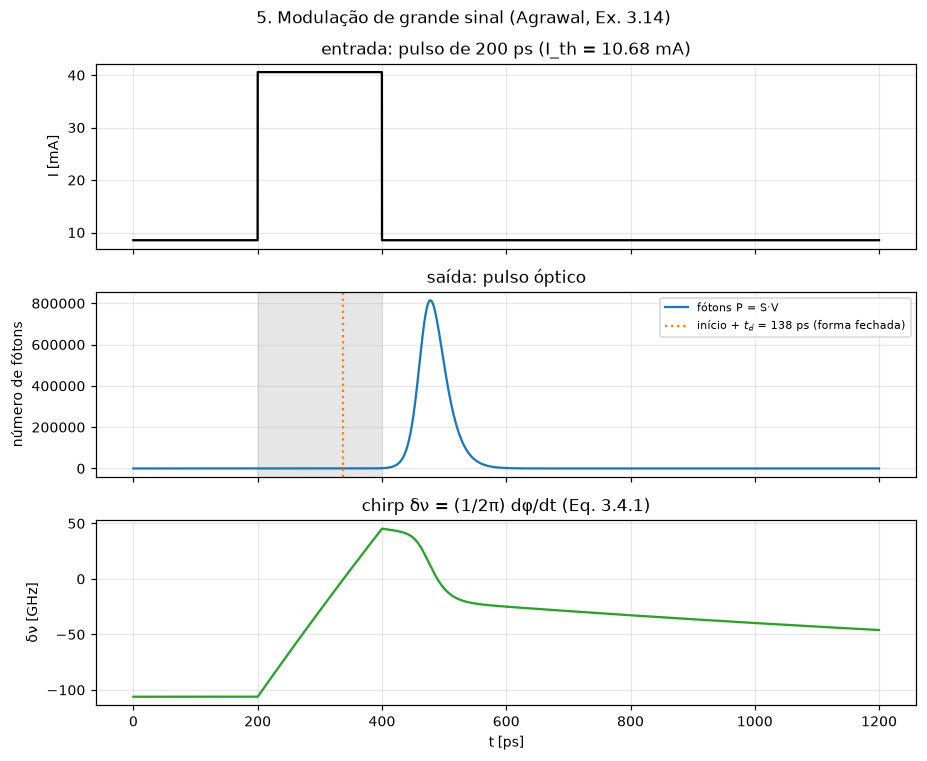

In [ ]:
V = R.volume
G_N, N0, tau_p, tau_c, eps_nl = 1e4, 1e8, 3e-12, 2e-9, 1e-7
P314 = RateEquationParams(gain_coefficient=G_N * V, transparency_density=N0 / V,
                          photon_lifetime=tau_p, carrier_lifetime=tau_c, volume=V,
                          spontaneous_emission_rate=(2 / tau_p) / V,
                          gain_compression=eps_nl * V, linewidth_enhancement=5.0)
I_th314 = Q_ELECTRON * (N0 + 1 / (G_N * tau_p)) / tau_c
I_b, I_m = 0.8 * I_th314, 3 * I_th314
dt5 = 0.1e-12
t5 = np.arange(int(1.2e-9 / dt5)) * dt5
t_ini = 0.2e-9
I_t = np.where((t5 >= t_ini) & (t5 < t_ini + 200e-12), I_b + I_m, I_b)
n0, s0 = steady_state(I_b, P314)
N5, S5, phi5 = integrate(I_t, dt5, P314, n0, s0)
chirp = np.gradient(phi5, dt5) / (2 * np.pi)
td = tau_c * np.log((I_b + I_m - I_b) / (I_b + I_m - I_th314))

fig, ax = plt.subplots(3, 1, figsize=(8.5, 7), sharex=True)
ax[0].plot(t5 * 1e12, I_t * 1e3, color="k")
ax[0].set(ylabel="I [mA]", title=f"entrada: pulso de 200 ps (I_th = {I_th314*1e3:.2f} mA)")
ax[1].plot(t5 * 1e12, S5 * V, color=C3[0], label="fótons P = S·V")
ax[1].axvline((t_ini + td) * 1e12, color=C3[1], ls=":",
              label=f"início + $t_d$ = {td*1e12:.0f} ps (forma fechada)")
ax[1].axvspan(t_ini * 1e12, (t_ini + 200e-12) * 1e12, color="0.9", zorder=0)
ax[1].set(ylabel="número de fótons", title="saída: pulso óptico")
ax[1].legend()
ax[2].plot(t5 * 1e12, chirp / 1e9, color=C3[2])
ax[2].set(xlabel="t [ps]", ylabel="δν [GHz]", title="chirp δν = (1/2π) dφ/dt (Eq. 3.4.1)")
fig.suptitle("5. Modulação de grande sinal (Agrawal, Ex. 3.14)")
fig.tight_layout()
larg = t5[S5 > 0.5 * S5.max()]
print(f"t_d (forma fechada) = {td*1e12:.0f} ps | luz acima de 50 % do pico durante "
      f"{(larg[-1]-larg[0])*1e12:.0f} ps, de {(larg[0]-t_ini)*1e12:.0f} a "
      f"{(larg[-1]-t_ini)*1e12:.0f} ps após o início do pulso de corrente")

**Leitura.**
- N atinge o limiar ~138 ps depois do início do pulso de corrente, como prevê $t_d$. Dos
  200 ps de corrente, sobram ~60 ps com N acima do limiar; nesse intervalo os fótons crescem
  a partir da semente de emissão espontânea, e N continua subindo.
- Quando a corrente desliga, N está acima do limiar e cai devagar ($\tau_c$ = 2 ns): os
  fótons continuam crescendo, consomem os portadores de uma vez e formam um único pico
  (uma oscilação de relaxação). Por isso o pulso óptico sai **depois** do fim do pulso de
  corrente e é bem mais curto que ele (ver a saída da célula): é a resposta do exercício.
  Com $I_b = I_{th}$, como na Fig. 3.16 do Agrawal, o atraso seria muito menor.
- Antes do pulso o chirp é constante e negativo: abaixo do limiar N < $N_{th}$, e a Eq. 3.4.1
  mede a frequência em relação à da condição de limiar. Durante o pulso de luz o chirp vai
  de positivo (frente) a negativo (cauda), como descreve o Agrawal para a Fig. 3.16
  ("primeiro para o azul, depois para o vermelho"). O sinal físico da frequência depende da
  convenção da portadora; aqui δν é a derivada da fase do envelope, como na Eq. 3.4.1.

Sem forma fechada para a forma do pulso; o comportamento do integrador está garantido pelos
testes do passo 4.

## 6. Modelo B: laser quase-monocromático (CW)

**Conceito.** Em modulação externa o laser opera em corrente constante e só a fase
flutua. O campo é $E(t) = \sqrt{P}\,e^{i[2\pi\Delta f\,t + \phi(t)]}$, com $\phi$ um passeio
aleatório (Agrawal, Eq. 3.3.33–3.3.37; código do professor `single_frequency_laser`).

**Forma fechada** [dedução, guia seção 2.2]:

$$\langle\Delta\phi^2(\tau)\rangle = 2\pi\,\Delta\nu\,\tau,\qquad
S(f) \propto \frac{1}{1 + [2(f - \Delta f)/\Delta\nu]^2}\quad\text{(lorentziana de largura } \Delta\nu)$$

A largura de linha de 10 MHz abaixo é exagerada em relação ao VPI (500 kHz) só para caber
numa janela curta; a forma não depende do valor.

erro relativo da variância: [-0.001 -0.001 -0.002 -0.003 -0.002 -0.002 -0.006 -0.011]


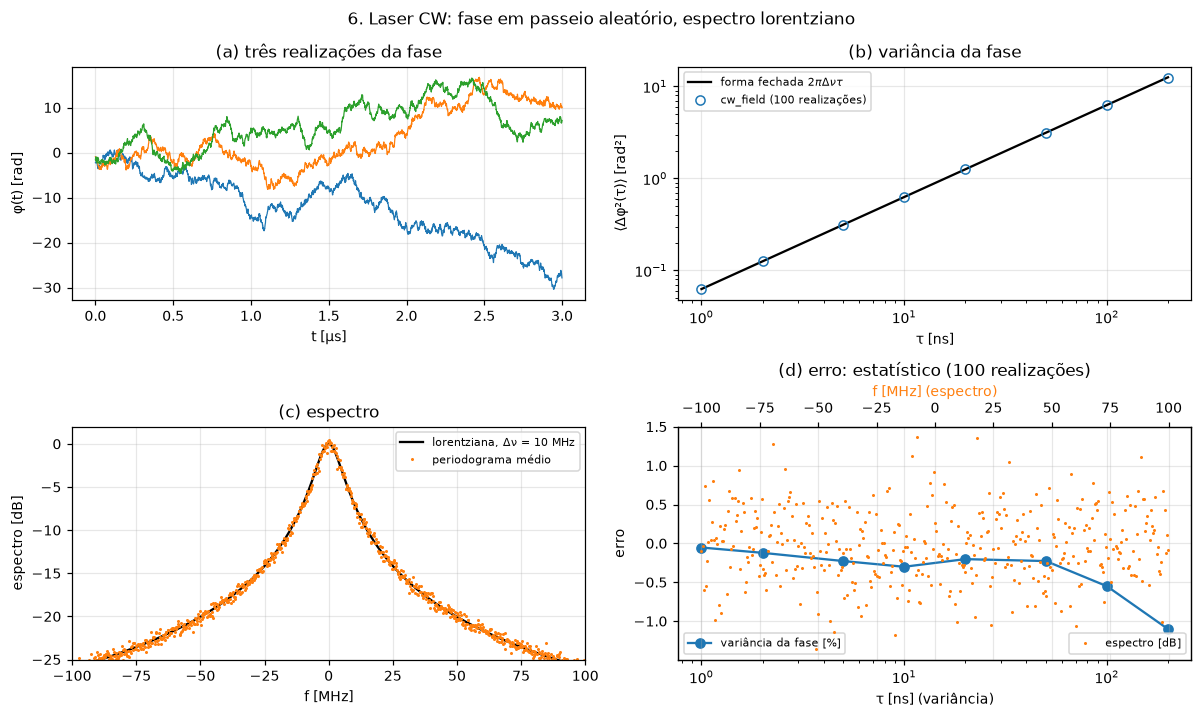

In [ ]:
DNU, FS6, N6, REAL = 10e6, 1e9, 2 ** 14, 100
dt6 = 1 / FS6
rng = np.random.default_rng(0)
campos = np.array([cw_field(N6, dt6, 1e-3, DNU, 0.0, rng) for _ in range(REAL)])
atrasos = np.array([1, 2, 5, 10, 20, 50, 100, 200])
fase = np.unwrap(np.angle(campos), axis=1)
var_med = [np.mean((fase[:, a:] - fase[:, :-a]) ** 2) for a in atrasos]
var_ana = 2 * np.pi * DNU * atrasos * dt6
f6 = np.fft.fftshift(np.fft.fftfreq(N6, dt6))
espec = np.fft.fftshift(np.mean(np.abs(np.fft.fft(campos, axis=1)) ** 2, axis=0))
lorentz = 1 / (1 + (2 * f6 / DNU) ** 2)
# Normaliza pela área (potência total), não pelo pico: o pico do periodograma médio é um
# único bin, com ruído estatístico, e normalizar por ele deslocaria a curva inteira.
espec *= lorentz.sum() / espec.sum()

fig, ax = plt.subplots(2, 2, figsize=(11, 6.6))
ax = ax.ravel()
for k in range(3):
    ax[0].plot(np.arange(N6)[:3000] * dt6 * 1e6, fase[k, :3000], lw=0.8)
ax[0].set(xlabel="t [µs]", ylabel="φ(t) [rad]", title="(a) três realizações da fase")
ax[1].loglog(atrasos * dt6 * 1e9, var_ana, "k-", label=r"forma fechada $2\pi\Delta\nu\tau$")
ax[1].loglog(atrasos * dt6 * 1e9, var_med, "o", mfc="none", color=C3[0],
             label=f"cw_field ({REAL} realizações)")
ax[1].set(xlabel="τ [ns]", ylabel="⟨Δφ²(τ)⟩ [rad²]", title="(b) variância da fase")
ax[2].plot(f6 / 1e6, 10 * np.log10(lorentz), "k-", label=f"lorentziana, Δν = {DNU/1e6:.0f} MHz")
ax[2].plot(f6[::4] / 1e6, 10 * np.log10(espec[::4]), ".", ms=2, color=C3[1],
           label="periodograma médio")
ax[2].set(xlim=(-100, 100), ylim=(-25, 2), xlabel="f [MHz]", ylabel="espectro [dB]",
          title="(c) espectro")
banda = np.abs(f6) < 100e6
ax[3].plot(atrasos * dt6 * 1e9, (np.array(var_med) / var_ana - 1) * 100, "o-", color=C3[0],
           label="variância da fase [%]")
ax3b = ax[3].twiny()
ax3b.plot(f6[banda][::8] / 1e6, 10 * np.log10(espec[banda][::8] / lorentz[banda][::8]), ".",
          ms=2, color=C3[1], label="espectro [dB]")
ax3b.set_xlabel("f [MHz] (espectro)", color=C3[1])
ax[3].set(xscale="log", xlabel="τ [ns] (variância)", ylabel="erro",
          title="(d) erro: estatístico (100 realizações)")
ax[3].legend(loc="lower left"); ax3b.legend(loc="lower right")
for a in ax[1:3]: a.legend()
fig.suptitle("6. Laser CW: fase em passeio aleatório, espectro lorentziano")
fig.tight_layout()
print("erro relativo da variância:", np.round(np.array(var_med) / var_ana - 1, 3))

**Leitura.** A variância da fase cresce linearmente com τ (reta de inclinação 1 em escala
log-log), e o espectro médio segue a lorentziana de largura Δν: as duas formas fechadas
da seção 2 do guia. O erro de (b) é estatístico (100 realizações) e cai com mais
realizações. A potência $|E|^2$ não muda com o ruído de fase.

Testes que garantem: `kernels/laser/tests/test_cw.py` (potência constante, variância dos
incrementos, autocorrelação lorentziana, tom puro com Δν = 0, fase inicial uniforme,
determinismo).

## Próximos passos (guia, seção 5)

- Passo 5: resposta de pequeno sinal $H(\omega_m)$ contra a Eq. 3.3.22.
- Passo 7: forças de Langevin no modelo A (ruído de intensidade e largura de linha contra a
  Eq. 3.3.37).
- Passo 8: blocos `CWLaser` e `DirectModulatedLaser`, que devolvem o campo (2, N) com a
  polarização Y em zero.